# 💳 Riesgo de crédito con XGBoost: predicción de morosidad explicable y responsable
### Early stopping, restricciones monotónicas, explicaciones por cliente, auditoría de equidad y umbral por pérdida esperada

**Autor:** Cristobal Rojas · **Herramientas:** Python, pandas, scikit-learn, XGBoost, matplotlib

---

## 🎯 Contexto de negocio

Un emisor de tarjetas de crédito quiere anticipar qué clientes **no pagarán su próxima cuota** para actuar antes: cobranza preventiva, reestructuración o ajuste del cupo. Un modelo de riesgo en banca no solo debe predecir bien, también tiene que:

1. **Ser coherente con el negocio:** más meses de atraso nunca deberían *bajar* el riesgo.
2. **Ser explicable cliente a cliente:** por qué se marcó a una persona como riesgosa.
3. **No discriminar:** el sexo o el estado civil no deberían decidir el resultado.
4. **Optimizar dinero, no exactitud:** un mal pagador no detectado cuesta mucho más que una llamada de cobranza innecesaria.

**Dataset:** [Default of Credit Card Clients — Kaggle (UCI)](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset) · 30.000 clientes de un banco de Taiwán (abr-sep 2005) · historial de 6 meses de pagos, facturación y abonos. Montos en nuevos dólares taiwaneses (NT$). Fuente original: Yeh y Lien (2009).

**Tercer proyecto de la serie:** árbol de decisión → random forest → **XGBoost**.

## 🧭 Hoja de ruta
| # | Etapa | Qué aporta |
|---|---|---|
| 1 | Auditoría de datos | Códigos **no documentados** en el diccionario oficial |
| 2 | EDA | El comportamiento de pago domina el riesgo |
| 3 | Ingeniería de variables | Utilización del cupo, tasa de pago, meses en mora |
| 4 | XGBoost "de curso" vs. **early stopping** | Por qué 5 árboles no bastan |
| 5 | **Restricciones monotónicas** | Un modelo que respeta la lógica de negocio |
| 6 | Benchmark de la serie | Árbol vs. random forest vs. XGBoost |
| 7 | **Explicaciones por cliente** (TreeSHAP nativo) | Por qué *este* cliente es riesgoso |
| 8 | **Auditoría de equidad** | ¿El modelo trata distinto a hombres y mujeres? |
| 9 | **Umbral por pérdida esperada** + bandas de riesgo | Del modelo a la política de crédito |

In [1]:
# ==== Importaciones ====
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, ParameterSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import partial_dependence
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 0
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

# ==== Estilo visual del proyecto ====
AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

print("XGBoost", xgb.__version__)

XGBoost 3.4.1


## 1. Carga y auditoría de datos
Descarga `UCI_Credit_Card.csv` desde Kaggle y ubícalo en la carpeta `data/`.

In [2]:
rutas = [Path("../data/UCI_Credit_Card.csv"), Path("data/UCI_Credit_Card.csv"), Path("UCI_Credit_Card.csv")]
ruta = next((r for r in rutas if r.exists()), None)
assert ruta is not None, "Descarga UCI_Credit_Card.csv desde Kaggle y ubícalo en data/ (o junto al notebook en Colab)"
df_original = pd.read_csv(ruta)
df_original = df_original.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"})
print(f"Clientes: {es(len(df_original))} | Variables: {df_original.shape[1]} | "
      f"Faltantes: {df_original.isna().sum().sum()} | Tasa de morosidad: {df_original['default'].mean():.1%}")
df_original.head()

Clientes: 30.000 | Variables: 25 | Faltantes: 0 | Tasa de morosidad: 22.1%


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


> `PAY_0` se renombra como `PAY_1` para que la secuencia de meses sea coherente (`PAY_1` = septiembre … `PAY_6` = abril), igual que `BILL_AMT1..6` y `PAY_AMT1..6`.

### 1.1 Cero faltantes… pero códigos que el diccionario no explica
Según la documentación oficial: `EDUCATION` ∈ {1 posgrado, 2 universitaria, 3 secundaria, 4 otros}, `MARRIAGE` ∈ {1 casado, 2 soltero, 3 otros} y `PAY_n` = −1 "pagó a tiempo", 1…9 "meses de atraso". Veamos qué hay realmente:

In [3]:
doc = {"EDUCATION": {1, 2, 3, 4}, "MARRIAGE": {1, 2, 3}, "PAY_1": {-1, 1, 2, 3, 4, 5, 6, 7, 8, 9}}
for col, validos in doc.items():
    vc = df_original[col].value_counts().sort_index()
    raros = vc[~vc.index.isin(validos)]
    print(f"{col:<10} códigos no documentados: { {int(k): int(v) for k, v in raros.items()} }  → {raros.sum():,} filas ({raros.sum()/len(df_original):.1%})".replace(",", "."))

EDUCATION  códigos no documentados: {0: 14. 5: 280. 6: 51}  → 345 filas (1.1%)
MARRIAGE   códigos no documentados: {0: 54}  → 54 filas (0.2%)
PAY_1      códigos no documentados: {-2: 2759. 0: 14737}  → 17.496 filas (58.3%)


**Diagnóstico y decisión:**
- `EDUCATION` 0, 5 y 6 (345 clientes) y `MARRIAGE` 0 (54) son categorías sin definición: se agrupan en **"otros"**.
- En `PAY_n`, los códigos **−2 y 0 abarcan el 58 % de los datos**: no pueden ser errores. Según aclaraciones posteriores de los autores del dataset, **−2 = sin consumo en el mes** y **0 = pago del mínimo (crédito rotativo)**. Se conservan, pero se crean variables explícitas (`meses_en_mora`, `max_atraso`) para que el significado no dependa de códigos ambiguos.

Validar los datos contra su documentación, y no solo contar nulos, es el tipo de revisión que evita modelos construidos sobre supuestos falsos.

In [4]:
df = df_original.drop(columns="ID").copy()
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print("Perfiles duplicados (mismas 23 variables):", df.duplicated().sum(), "→ se conservan: son clientes distintos")

Perfiles duplicados (mismas 23 variables): 35 → se conservan: son clientes distintos


## 2. Análisis exploratorio (EDA)

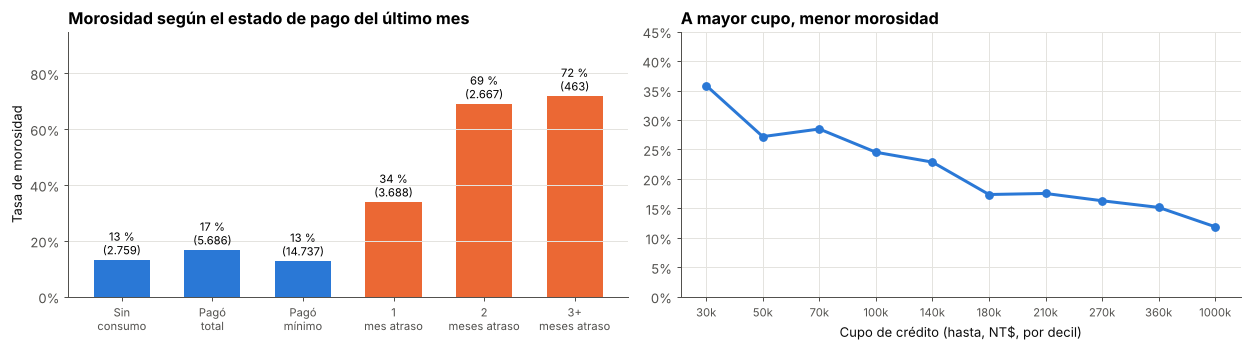

In [5]:
estado = df["PAY_1"].clip(upper=3).map({-2: "Sin consumo", -1: "Pagó total", 0: "Pagó mínimo",
                                         1: "1 mes atraso", 2: "2 meses atraso", 3: "3+ meses atraso"})
orden = ["Sin consumo", "Pagó total", "Pagó mínimo", "1 mes atraso", "2 meses atraso", "3+ meses atraso"]
t = df.groupby(estado)["default"].agg(["mean", "size"]).reindex(orden)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
ax.bar(range(len(t)), t["mean"], color=[AZUL] * 3 + [NARANJA] * 3, width=0.62)
for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
    ax.text(i, m + 0.02, f"{m*100:.0f} %\n({es(n)})", ha="center", fontsize=9)
ax.set_xticks(range(len(t)), [o.replace(" ", "\n", 1) for o in orden], fontsize=9)
ax.set_ylim(0, 0.95); ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
ax.set_title("Morosidad según el estado de pago del último mes"); ax.set_ylabel("Tasa de morosidad")

ax = axes[1]
dec = pd.qcut(df["LIMIT_BAL"], 10, duplicates="drop")
t2 = df.groupby(dec, observed=True)["default"].mean()
etq = [f"{int(i.right/1000)}k" for i in t2.index]
ax.plot(range(len(t2)), t2.values, "-o", color=AZUL, lw=2.4, ms=6)
ax.set_xticks(range(len(t2)), etq, fontsize=9); ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 0.45); ax.set_xlabel("Cupo de crédito (hasta, NT$, por decil)")
ax.set_title("A mayor cupo, menor morosidad")
plt.tight_layout()
guardar("01_eda_estado_pago_cupo")

**Hallazgos del EDA**
- El **estado de pago del último mes** separa el riesgo de forma brutal: quienes pagaron el total o no usaron la tarjeta incumplen alrededor del 13-17 %, y quienes acumulan 2 o más meses de atraso, sobre el 69 %.
- El **cupo** es un buen proxy de la evaluación previa del banco: los clientes con cupos bajos incumplen cerca del triple que los de cupos altos.
- La clase está desbalanceada (22 % de morosidad), así que la exactitud por sí sola engaña.

## 3. Ingeniería de variables de comportamiento
Los modelos de riesgo reales se basan en **comportamiento**, no en datos demográficos:
- `utilizacion_k`: deuda facturada / cupo (qué tan "estirado" está el cliente).
- `tasa_pago_k`: abono del mes / facturación del mes anterior (cuánto de la deuda paga realmente).
- `meses_en_mora`, `max_atraso`: resumen del historial de atrasos.
- `tendencia_deuda`: variación de la facturación entre abril y septiembre.

In [6]:
datos = df.copy()
for k in range(1, 7):
    datos[f"utilizacion_{k}"] = (datos[f"BILL_AMT{k}"] / datos["LIMIT_BAL"]).clip(-1, 3)
for k in range(1, 6):
    prev = datos[f"BILL_AMT{k+1}"]
    datos[f"tasa_pago_{k}"] = np.where(prev > 0, datos[f"PAY_AMT{k}"] / prev.clip(lower=1), 1).clip(0, 2)
pays = datos[[f"PAY_{k}" for k in range(1, 7)]]
datos["meses_en_mora"] = (pays > 0).sum(axis=1)
datos["max_atraso"] = pays.clip(lower=0).max(axis=1)
datos["utilizacion_media"] = datos[[f"utilizacion_{k}" for k in range(1, 7)]].mean(axis=1)
datos["tasa_pago_media"] = datos[[f"tasa_pago_{k}" for k in range(1, 6)]].mean(axis=1)
datos["tendencia_deuda"] = (datos["BILL_AMT1"] - datos["BILL_AMT6"]) / datos["LIMIT_BAL"]

datos = pd.get_dummies(datos, columns=["EDUCATION", "MARRIAGE"], dtype=int)
datos["es_mujer"] = (datos.pop("SEX") == 2).astype(int)
y = datos.pop("default")
X_completo = datos
print("Variables:", X_completo.shape[1])

Variables: 44


### División estratificada: entrenamiento 60 % · validación 20 % · prueba 20 %
La validación se usa para el **early stopping** y para elegir el umbral; la prueba se toca una sola vez.

In [7]:
X_tmp, X_te, y_tmp, y_te = train_test_split(X_completo, y, test_size=0.2, stratify=y, random_state=SEED)
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
for n, a, b in [("Entrenamiento", X_tr, y_tr), ("Validación", X_val, y_val), ("Prueba", X_te, y_te)]:
    print(f"{n:<14} {es(len(a)):>6} clientes | morosidad {b.mean():.1%}")

def metricas(p, y_, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, p), "PR-AUC": average_precision_score(y_, p)}

Entrenamiento  18.000 clientes | morosidad 22.1%
Validación      6.000 clientes | morosidad 22.1%
Prueba          6.000 clientes | morosidad 22.1%


## 4. XGBoost "de curso" vs. XGBoost con early stopping
### 4.1 La configuración típica de un ejercicio introductorio
Por limitaciones de tiempo, es común ver una grilla con **`n_estimators=5`**: solo 5 árboles. Reproduzcámosla:

In [8]:
grilla_curso = {"max_depth": [4], "min_child_weight": [3], "learning_rate": [0.1],
                "n_estimators": [5], "subsample": [0.7], "colsample_bytree": [0.7]}
gs = GridSearchCV(XGBClassifier(objective="binary:logistic", random_state=SEED, n_jobs=-1),
                  grilla_curso, scoring="f1", cv=5).fit(X_tr, y_tr)
xgb_curso = gs.best_estimator_
p_curso = xgb_curso.predict_proba(X_te)[:, 1]
print(f"Probabilidades predichas: mín {p_curso.min():.2f} · máx {p_curso.max():.2f}")
pd.Series(metricas(p_curso, y_te)).round(3)

Probabilidades predichas: mín 0.16 · máx 0.45


Accuracy     0.779
Precision    0.000
Recall       0.000
F1           0.000
ROC-AUC      0.777
PR-AUC       0.555
dtype: float64

Con 5 árboles y `learning_rate=0.1`, el modelo apenas alcanza a alejarse de su punto de partida: **todas las probabilidades quedan entre 0,16 y 0,45**, así que con el umbral de 0,5 **no marca a ningún cliente como moroso** (recall y F1 = 0). Su exactitud de 77,9 % es idéntica a predecir siempre "paga". Curiosamente, su ROC-AUC (0,777) no es mala: ordena razonablemente a los clientes, pero sus probabilidades no sirven para decidir. **El problema no es XGBoost, es la configuración.** El *boosting* construye árboles en secuencia, cada uno corrigiendo al anterior, y necesita cientos de pasos pequeños.

### 4.2 Early stopping: que el modelo decida cuántos árboles necesita
En vez de adivinar `n_estimators`, se fija un máximo alto (3.000) y se **detiene el entrenamiento cuando la pérdida en validación deja de mejorar durante 100 rondas**. Se combina con una búsqueda aleatoria liviana de los demás hiperparámetros.

In [9]:
espacio = {"max_depth": [3, 4, 5, 6], "min_child_weight": [1, 5, 10, 20],
           "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.5, 0.7, 0.9],
           "reg_lambda": [1, 5, 10], "gamma": [0, 0.5, 1]}
resultados = []
t0 = time.time()
for params in ParameterSampler(espacio, n_iter=25, random_state=SEED):
    m = XGBClassifier(n_estimators=3000, learning_rate=0.03, early_stopping_rounds=100,
                      eval_metric="logloss", random_state=SEED, n_jobs=-1, **params)
    m.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    resultados.append({**params, "arboles": m.best_iteration + 1,
                       "auc_val": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
res = pd.DataFrame(resultados).sort_values("auc_val", ascending=False)
mejores = res.iloc[0].drop(["arboles", "auc_val"]).to_dict()
mejores = {k: (int(v) if k in ("max_depth", "min_child_weight") else float(v)) for k, v in mejores.items()}
print(f"25 configuraciones evaluadas en {time.time() - t0:.0f} s")
print("Mejores hiperparámetros:", mejores, "| árboles elegidos por early stopping:", int(res.iloc[0]["arboles"]))
res.head(5).round(4)

25 configuraciones evaluadas en 30 s
Mejores hiperparámetros: {'subsample': 0.7, 'reg_lambda': 10.0, 'min_child_weight': 1, 'max_depth': 4, 'gamma': 1.0, 'colsample_bytree': 0.9} | árboles elegidos por early stopping: 345


,subsample,reg_lambda,min_child_weight,max_depth,gamma,colsample_bytree,arboles,auc_val
6,0.7,10,1,4,1.0,0.9,345,0.7916
7,0.7,5,5,5,0.0,0.9,217,0.7915
5,0.7,10,10,3,1.0,0.5,433,0.7911
19,0.7,1,10,4,0.0,0.7,346,0.7911
1,0.7,10,1,4,0.0,0.7,285,0.7908


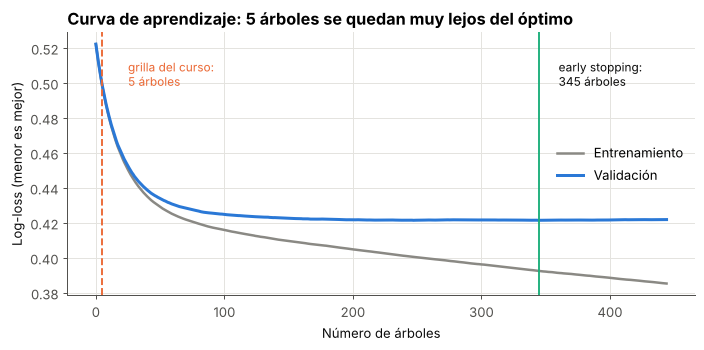

In [10]:
xgb_es = XGBClassifier(n_estimators=3000, learning_rate=0.03, early_stopping_rounds=100,
                       eval_metric="logloss", random_state=SEED, n_jobs=-1, **mejores)
xgb_es.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=False)
hist = xgb_es.evals_result()
n_opt = xgb_es.best_iteration + 1

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(hist["validation_0"]["logloss"], color=GRIS, lw=2, label="Entrenamiento")
ax.plot(hist["validation_1"]["logloss"], color=AZUL, lw=2.4, label="Validación")
ax.axvline(n_opt, color=VERDE, lw=1.5)
ax.axvline(5, color=NARANJA, lw=1.5, ls="--")
ax.text(n_opt + 15, ax.get_ylim()[1] * 0.97, f"early stopping:\n{n_opt} árboles", color=TINTA, fontsize=9.5, va="top")
ax.text(25, ax.get_ylim()[1] * 0.97, "grilla del curso:\n5 árboles", color=NARANJA, fontsize=9.5, va="top")
ax.set_xlabel("Número de árboles"); ax.set_ylabel("Log-loss (menor es mejor)")
ax.set_title("Curva de aprendizaje: 5 árboles se quedan muy lejos del óptimo"); ax.legend(loc="center right")
guardar("02_early_stopping")

## 5. Restricciones monotónicas: un modelo que respeta la lógica de negocio
Un modelo sin restricciones puede aprender patrones absurdos por ruido, por ejemplo que **3 meses de atraso sean menos riesgosos que 2**. Ningún comité de riesgo aprobaría ese modelo, y en banca regulada es difícil de justificar.

XGBoost permite imponer **monotonía**: el riesgo solo puede **subir** con los meses en mora, el atraso máximo y la utilización, y solo puede **bajar** con el cupo y la tasa de pago.

> Los códigos originales `PAY_n` **no** se restringen: −2, −1 y 0 no tienen un orden de riesgo claro (en el EDA, "pagó total" tiene 17 % de morosidad y "pagó mínimo" 13 %). Por eso se crearon `meses_en_mora` y `max_atraso`, que sí son monótonas por construcción. La auditoría del paso 1 condiciona el diseño del modelo.

In [11]:
reglas = {"meses_en_mora": 1, "max_atraso": 1, "utilizacion_1": 1, "utilizacion_media": 1,
          "LIMIT_BAL": -1, "tasa_pago_1": -1, "tasa_pago_media": -1}
restricciones = tuple(reglas.get(c, 0) for c in X_completo.columns)

xgb_mono = XGBClassifier(n_estimators=3000, learning_rate=0.03, early_stopping_rounds=100,
                         eval_metric="logloss", random_state=SEED, n_jobs=-1,
                         monotone_constraints=restricciones, **mejores)
xgb_mono.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f"ROC-AUC prueba → sin restricciones: {roc_auc_score(y_te, xgb_es.predict_proba(X_te)[:, 1]):.4f} | "
      f"con restricciones: {roc_auc_score(y_te, xgb_mono.predict_proba(X_te)[:, 1]):.4f}")

ROC-AUC prueba → sin restricciones: 0.7899 | con restricciones: 0.7891


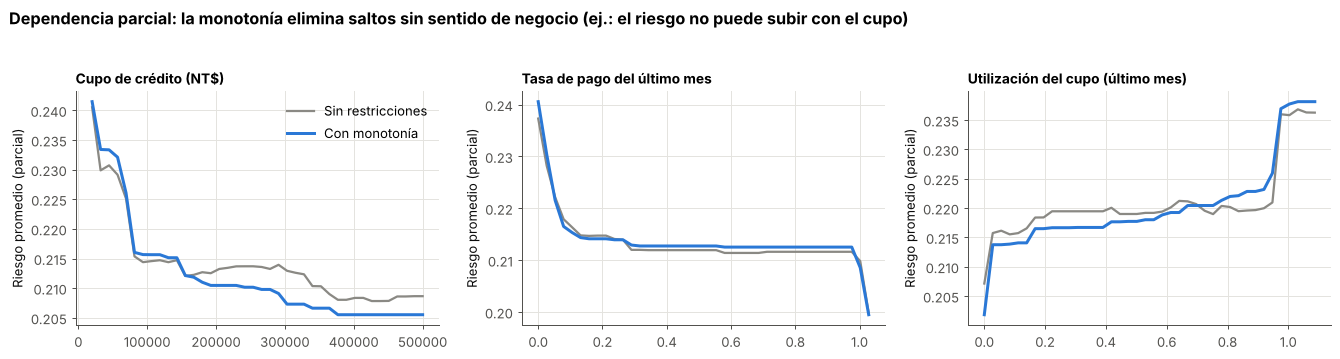

In [12]:
muestra = X_te.sample(3000, random_state=SEED).astype(float)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, var, titulo in zip(axes, ["LIMIT_BAL", "tasa_pago_1", "utilizacion_1"],
                           ["Cupo de crédito (NT$)", "Tasa de pago del último mes", "Utilización del cupo (último mes)"]):
    for modelo, color, nombre in [(xgb_es, GRIS, "Sin restricciones"), (xgb_mono, AZUL, "Con monotonía")]:
        pdp = partial_dependence(modelo, muestra, [var], grid_resolution=40, percentiles=(0.02, 0.98))
        ax.plot(pdp["grid_values"][0], pdp["average"][0], color=color, lw=2.4 if color == AZUL else 1.8, label=nombre)
    ax.set_title(titulo, fontsize=11); ax.set_ylabel("Riesgo promedio (parcial)")
axes[0].legend()
fig.suptitle("Dependencia parcial: la monotonía elimina saltos sin sentido de negocio (ej.: el riesgo no puede subir con el cupo)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
guardar("03_monotonia")

El modelo con restricciones produce curvas **suaves y defendibles** ante un comité de riesgo, con un costo predictivo mínimo. Es el modelo que se usa en adelante.

## 6. Benchmark de la serie: árbol vs. random forest vs. XGBoost
Todos entrenados con los mismos datos y evaluados en el mismo conjunto de prueba.

In [13]:
X_trval, y_trval = pd.concat([X_tr, X_val]), pd.concat([y_tr, y_val])
arbol = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED).fit(X_trval, y_trval)
bosque = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, max_features=0.3,
                                n_jobs=-1, random_state=SEED).fit(X_trval, y_trval)
probas = {"Árbol de decisión": arbol.predict_proba(X_te)[:, 1],
          "Random Forest": bosque.predict_proba(X_te)[:, 1],
          "XGBoost 'de curso' (5 árboles)": p_curso,
          "XGBoost early stopping": xgb_es.predict_proba(X_te)[:, 1],
          "XGBoost monotónico": xgb_mono.predict_proba(X_te)[:, 1]}
tabla = pd.DataFrame({n: metricas(p, y_te) for n, p in probas.items()}).T.round(3)
tabla.to_csv(REP / "comparacion_modelos.csv")
tabla

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Árbol de decisión,0.817,0.650,0.377,0.477,0.775,0.545
Random Forest,0.820,0.667,0.375,0.480,0.780,0.564
XGBoost 'de curso' (5 árboles),0.779,0.000,0.000,0.000,0.777,0.555
XGBoost early stopping,0.822,0.671,0.378,0.484,0.790,0.576
XGBoost monotónico,0.821,0.672,0.376,0.482,0.789,0.574


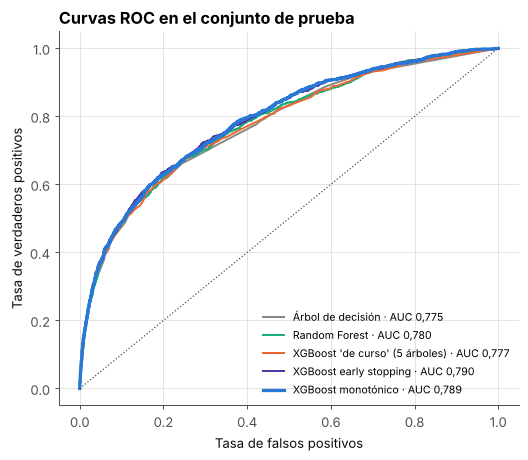

In [14]:
colores = {"Árbol de decisión": GRIS, "Random Forest": VERDE, "XGBoost 'de curso' (5 árboles)": NARANJA,
           "XGBoost early stopping": VIOLETA, "XGBoost monotónico": AZUL}
fig, ax = plt.subplots(figsize=(6.6, 5.4))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=colores[n], lw=2.6 if n == "XGBoost monotónico" else 1.6, label=f"{n} · AUC {es(roc_auc_score(y_te, p), 3)}")
ax.plot([0, 1], [0, 1], ":", color=TINTA2, lw=1)
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC en el conjunto de prueba"); ax.legend(loc="lower right", fontsize=8.5)
guardar("04_roc_serie")

## 7. Explicaciones por cliente con TreeSHAP nativo de XGBoost
XGBoost calcula los **valores SHAP** de forma exacta y nativa (`pred_contribs=True`), sin librerías adicionales. Cada valor indica cuánto empuja una variable el riesgo de *ese* cliente hacia arriba o hacia abajo (en escala log-odds).

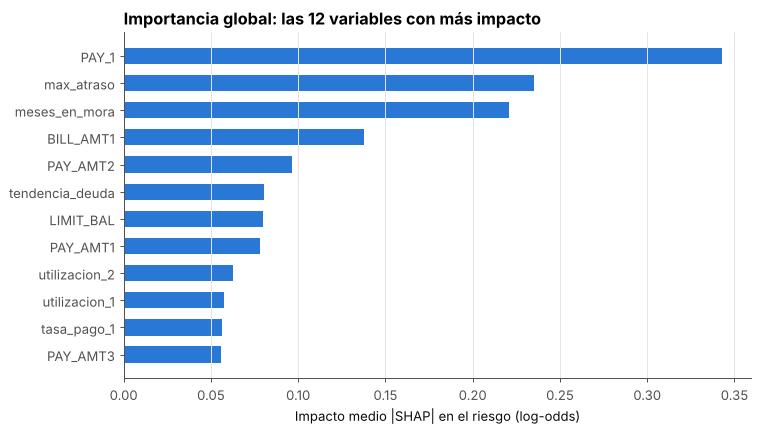

PAY_1              0.3426
max_atraso         0.2351
meses_en_mora      0.2208
BILL_AMT1          0.1376
PAY_AMT2           0.0962
tendencia_deuda    0.0806
LIMIT_BAL          0.0798
PAY_AMT1           0.0780
utilizacion_2      0.0625
utilizacion_1      0.0575
tasa_pago_1        0.0562
PAY_AMT3           0.0560
dtype: float32

In [15]:
dm = xgb.DMatrix(X_te)
contrib = xgb_mono.get_booster().predict(dm, pred_contribs=True, iteration_range=(0, xgb_mono.best_iteration + 1))
shap_df = pd.DataFrame(contrib[:, :-1], columns=X_te.columns, index=X_te.index)
base = contrib[0, -1]

imp = shap_df.abs().mean().sort_values(ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=AZUL, height=0.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("Impacto medio |SHAP| en el riesgo (log-odds)")
ax.set_title("Importancia global: las 12 variables con más impacto")
guardar("05_importancia_shap")
imp.iloc[::-1].round(4)

Riesgo base de la cartera: 22.0% → riesgo de este cliente: 81.2%


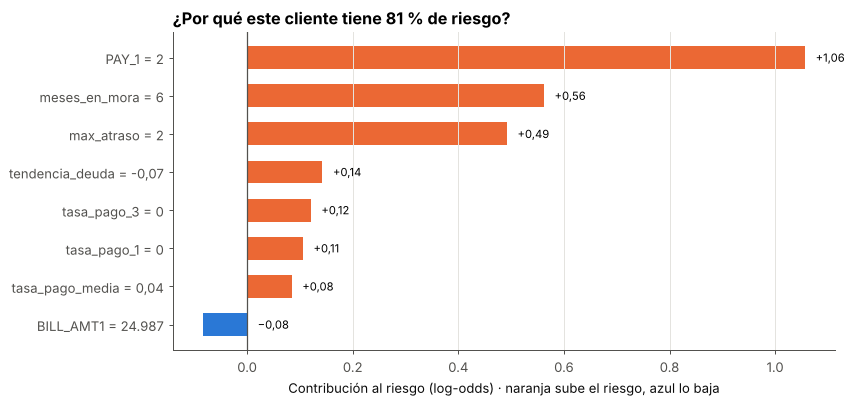

In [16]:
p_mono = probas["XGBoost monotónico"]
cliente = pd.Series(p_mono, index=X_te.index)[(y_te == 1).values].sort_values().index[-40]
s = shap_df.loc[cliente].sort_values(key=abs, ascending=False).head(8).iloc[::-1]
x = X_te.loc[cliente]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh([f"{c} = {es(x[c]) if float(x[c]).is_integer() else es(x[c], 2)}" for c in s.index], s.values,
        color=[NARANJA if v > 0 else AZUL for v in s.values], height=0.6)
ax.axvline(0, color=TINTA2, lw=1)
for i, v in enumerate(s.values):
    ax.text(max(v, 0) + 0.02, i, f"{v:+.2f}".replace(".", ",").replace("-", "−"), va="center",
            ha="left", fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribución al riesgo (log-odds) · naranja sube el riesgo, azul lo baja")
ax.set_title(f"¿Por qué este cliente tiene {p_mono[X_te.index.get_loc(cliente)]*100:.0f} % de riesgo?")
guardar("06_explicacion_cliente")
print(f"Riesgo base de la cartera: {1/(1+np.exp(-base)):.1%} → riesgo de este cliente: {p_mono[X_te.index.get_loc(cliente)]:.1%}")

Esta explicación se puede entregar al ejecutivo comercial o al cliente: *"su riesgo es alto principalmente por 2 meses de atraso en septiembre, atrasos en los 6 meses del historial y abonos prácticamente nulos respecto de su deuda"*. Es exactamente el tipo de justificación que piden los reguladores para decisiones automatizadas de crédito.

## 8. Auditoría de equidad
El dataset incluye **sexo** y **estado civil**, variables que no deberían influir en una decisión de crédito. Dos preguntas:
1. ¿Cuánto rendimiento se pierde si se eliminan del modelo?
2. ¿El modelo final comete errores distintos para hombres y mujeres?

In [17]:
protegidas = ["es_mujer"] + [c for c in X_completo.columns if c.startswith("MARRIAGE_")]
cols_justas = [c for c in X_completo.columns if c not in protegidas]
restr_justas = tuple(reglas.get(c, 0) for c in cols_justas)
xgb_justo = XGBClassifier(n_estimators=3000, learning_rate=0.03, early_stopping_rounds=100,
                          eval_metric="logloss", random_state=SEED, n_jobs=-1,
                          monotone_constraints=restr_justas, **mejores)
xgb_justo.fit(X_tr[cols_justas], y_tr, eval_set=[(X_val[cols_justas], y_val)], verbose=False)
p_justo = xgb_justo.predict_proba(X_te[cols_justas])[:, 1]
print(f"ROC-AUC con sexo y estado civil: {roc_auc_score(y_te, p_mono):.4f} | "
      f"sin ellos: {roc_auc_score(y_te, p_justo):.4f}")

ROC-AUC con sexo y estado civil: 0.7891 | sin ellos: 0.7896


Eliminar sexo y estado civil **prácticamente no cambia el rendimiento**: no aportan información que el comportamiento de pago no capture ya. Como no hay razón técnica para mantenerlos y sí una razón ética y regulatoria para quitarlos, **el modelo final los excluye**.

## 9. 💰 Del modelo a la política: umbral por pérdida esperada
Los errores no cuestan lo mismo. Se define un modelo económico simple (supuestos editables):

| Supuesto | Valor | Interpretación |
|---|---|---|
| `EXPOSICION` | Deuda facturada del último mes | Monto en riesgo por cliente |
| `LGD` | 60 % | Pérdida dado el incumplimiento (*loss given default*) |
| `EFECTIVIDAD` | 40 % | Fracción de la pérdida que evita la cobranza preventiva en un moroso real |
| `COSTO_FP` | 5 % de la exposición + NT$ 200 | Margen perdido y costo de gestión al molestar a un buen cliente |

**Ahorro neto(u)** = Σ_VP EFECTIVIDAD · LGD · exposición − Σ_FP (0,05 · exposición) − 200 · (VP + FP)

El umbral se elige en **validación** y se evalúa en **prueba**.

Umbral óptimo (validación): 0.19 | clientes marcados en prueba: 37.8%
Ahorro neto en prueba → umbral 0,5: NT$ 6.225.996 | umbral óptimo: NT$ 7.458.021 (+20%)
Pérdida esperada total de la cartera de prueba sin acción: NT$ 40.220.867


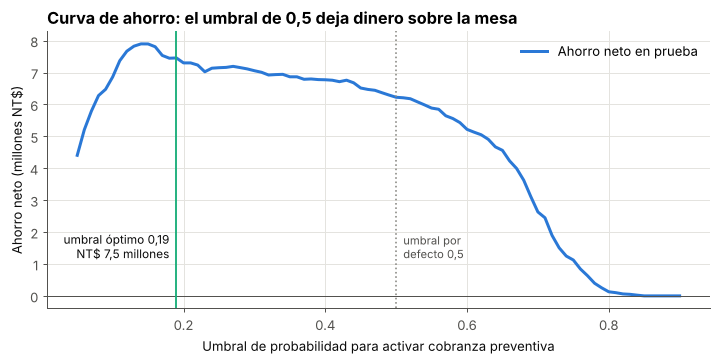

In [18]:
LGD, EFECTIVIDAD, COSTO_FP_PCT, COSTO_GESTION = 0.60, 0.40, 0.05, 200

def ahorro(y_real, prob, expo, u):
    marcar = prob >= u
    vp, fp = marcar & (y_real == 1), marcar & (y_real == 0)
    return (EFECTIVIDAD * LGD * expo[vp]).sum() - (COSTO_FP_PCT * expo[fp]).sum() - COSTO_GESTION * marcar.sum()

expo_val = X_val["BILL_AMT1"].clip(lower=0).values
expo_te = X_te["BILL_AMT1"].clip(lower=0).values
p_val = xgb_justo.predict_proba(X_val[cols_justas])[:, 1]
umbrales = np.round(np.arange(0.05, 0.91, 0.01), 2)
a_val = np.array([ahorro(y_val.values, p_val, expo_val, u) for u in umbrales])
u_opt = umbrales[a_val.argmax()]
a_te = np.array([ahorro(y_te.values, p_justo, expo_te, u) for u in umbrales])
a_opt, a_05 = ahorro(y_te.values, p_justo, expo_te, u_opt), ahorro(y_te.values, p_justo, expo_te, 0.5)
perdida_total = (LGD * expo_te[y_te.values == 1]).sum()
print(f"Umbral óptimo (validación): {u_opt:.2f} | clientes marcados en prueba: {(p_justo >= u_opt).mean():.1%}")
print(f"Ahorro neto en prueba → umbral 0,5: NT$ {es(a_05)} | umbral óptimo: NT$ {es(a_opt)} (+{a_opt/a_05-1:.0%})")
print(f"Pérdida esperada total de la cartera de prueba sin acción: NT$ {es(perdida_total)}")

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(umbrales, a_te / 1e6, color=AZUL, lw=2.4, label="Ahorro neto en prueba")
ax.axhline(0, color=TINTA2, lw=0.8)
ax.axvline(0.5, color=GRIS, ls=":", lw=1.3); ax.axvline(u_opt, color=VERDE, lw=1.5)
ax.text(0.51, a_te.max() / 1e6 * 0.15, "umbral por\ndefecto 0,5", color=TINTA2, fontsize=9)
ax.text(u_opt - 0.01, a_te.max() / 1e6 * 0.15, f"umbral óptimo {es(u_opt, 2)}\nNT$ {es(a_opt / 1e6, 1)} millones",
        color=TINTA, fontsize=9.5, ha="right")
ax.set_xlabel("Umbral de probabilidad para activar cobranza preventiva"); ax.set_ylabel("Ahorro neto (millones NT$)")
ax.set_title("Curva de ahorro: el umbral de 0,5 deja dinero sobre la mesa"); ax.legend(loc="upper right")
guardar("07_curva_ahorro")

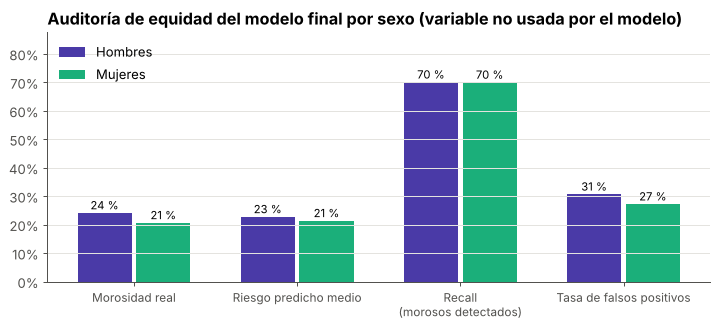

,Clientes,Morosidad real,Riesgo predicho medio,Recall (morosos detectados),Tasa de falsos positivos,ROC-AUC
Grupo,,,,,,
Hombres,2436,0.242,0.228,0.701,0.308,0.779
Mujeres,3564,0.207,0.214,0.701,0.273,0.797


In [19]:
# Auditoría de equidad del modelo final (sin variables protegidas), al umbral de negocio
aud = pd.DataFrame({"sexo": np.where(X_te["es_mujer"] == 1, "Mujeres", "Hombres"),
                    "y": y_te.values, "marcado": (p_justo >= u_opt).astype(int), "p": p_justo})
filas = []
for g, d in aud.groupby("sexo"):
    filas.append({"Grupo": g, "Clientes": len(d), "Morosidad real": d["y"].mean(), "Riesgo predicho medio": d["p"].mean(),
                  "Recall (morosos detectados)": d.loc[d.y == 1, "marcado"].mean(),
                  "Tasa de falsos positivos": d.loc[d.y == 0, "marcado"].mean(),
                  "ROC-AUC": roc_auc_score(d["y"], d["p"])})
equidad = pd.DataFrame(filas).set_index("Grupo")
equidad.to_csv(REP / "auditoria_equidad.csv")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
metr = ["Morosidad real", "Riesgo predicho medio", "Recall (morosos detectados)", "Tasa de falsos positivos"]
xx = np.arange(len(metr)); w = 0.36
for k, (g, c) in enumerate([("Hombres", VIOLETA), ("Mujeres", VERDE)]):
    v = equidad.loc[g, metr].values
    ax.bar(xx + (k - 0.5) * w, v, w * 0.92, color=c, label=g)
    for xi, vi in zip(xx + (k - 0.5) * w, v):
        ax.text(xi, vi + 0.012, f"{vi*100:.0f} %", ha="center", fontsize=9)
ax.set_xticks(xx, [m.replace(" (", "\n(") for m in metr], fontsize=9.5)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, max(equidad[metr].max()) * 1.25); ax.grid(axis="x", visible=False)
ax.set_title("Auditoría de equidad del modelo final por sexo (variable no usada por el modelo)"); ax.legend(loc="upper left")
guardar("08_equidad")
equidad.round(3)

El modelo final **no usa el sexo**, y aun así se verifica su comportamiento por grupo:
- El **riesgo predicho medio** sigue de cerca la morosidad real de cada grupo (no sobreestima a ninguno).
- La **tasa de detección de morosos es idéntica** (70 % en ambos grupos).
- La **tasa de falsos positivos es 4 puntos mayor en hombres** (31 % vs. 27 %), coherente con su mayor morosidad real (24 % vs. 21 %). No es un sesgo del modelo, pero es una brecha que conviene **monitorear** en producción.

Excluir una variable protegida no garantiza equidad por sí solo (otras variables pueden actuar como proxy), por eso la auditoría por grupo es indispensable.

### 9.1 Bandas de riesgo para la política de crédito

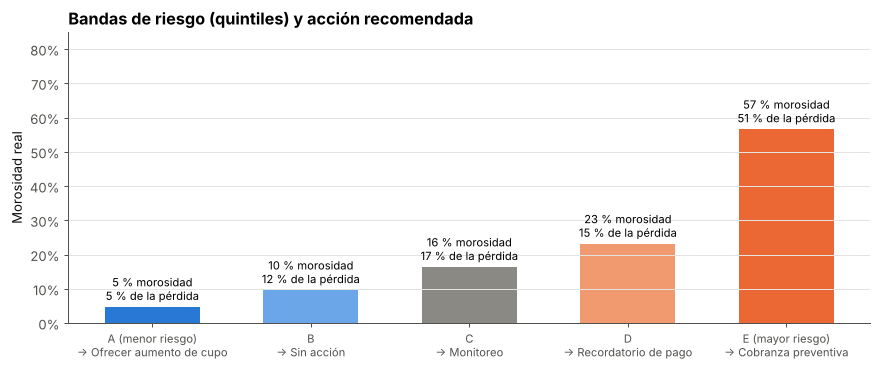

,clientes,riesgo_predicho,morosidad_real,perdida_ntd,% de la pérdida
banda,,,,,
A (menor riesgo),1200,0.054,0.048,2161593.6,0.054
B,1200,0.097,0.097,4669878.0,0.116
C,1200,0.149,0.164,6993883.2,0.174
D,1203,0.240,0.232,5951914.8,0.148
E (mayor riesgo),1197,0.561,0.566,20443597.2,0.508


In [20]:
bandas = pd.qcut(p_justo, 5, labels=["A (menor riesgo)", "B", "C", "D", "E (mayor riesgo)"])
pol = (pd.DataFrame({"banda": bandas, "y": y_te.values, "p": p_justo,
                     "perdida": LGD * expo_te * y_te.values})
         .groupby("banda", observed=True)
         .agg(clientes=("y", "size"), riesgo_predicho=("p", "mean"), morosidad_real=("y", "mean"),
              perdida_ntd=("perdida", "sum")))
pol["% de la pérdida"] = pol["perdida_ntd"] / pol["perdida_ntd"].sum()
pol.to_csv(REP / "bandas_riesgo.csv")
acciones = ["Ofrecer aumento de cupo", "Sin acción", "Monitoreo", "Recordatorio de pago", "Cobranza preventiva"]

fig, ax = plt.subplots(figsize=(11.5, 4.2))
cols_b = [AZUL, "#6aa6e8", GRIS, "#f19a6f", NARANJA]
ax.bar(range(5), pol["morosidad_real"], color=cols_b, width=0.6)
for i, (b, r) in enumerate(pol.iterrows()):
    ax.text(i, r["morosidad_real"] + 0.02, f"{r['morosidad_real']*100:.0f} % morosidad\n{r['% de la pérdida']*100:.0f} % de la pérdida",
            ha="center", fontsize=9)
ax.set_xticks(range(5), [f"{b}\n→ {a}" for b, a in zip(pol.index, acciones)], fontsize=9)
ax.set_ylim(0, 0.85); ax.yaxis.set_major_formatter(PCT); ax.grid(axis="x", visible=False)
ax.set_ylabel("Morosidad real"); ax.set_title("Bandas de riesgo (quintiles) y acción recomendada")
guardar("09_bandas_riesgo")
pol.round(3)

In [21]:
import joblib
joblib.dump({"modelo": xgb_justo, "columnas": cols_justas, "umbral": float(u_opt)},
            REP / "modelo_xgboost_credito.joblib", compress=3)
print("Modelo final guardado en reports/modelo_xgboost_credito.joblib")

Modelo final guardado en reports/modelo_xgboost_credito.joblib


## 10. Conclusiones y recomendaciones

**Hallazgos clave**
1. **XGBoost no "rinde peor" que un random forest: estaba mal configurado.** Con solo 5 árboles no detecta ni un moroso; con early stopping elige 345 árboles y obtiene el mejor ROC-AUC de la serie (0,790 vs. 0,780 del random forest y 0,775 del árbol). En este dataset el margen entre modelos es estrecho: el valor diferencial está en la coherencia, la explicabilidad y la decisión de negocio.
2. **Las restricciones monotónicas casi no cuestan rendimiento** y entregan un modelo coherente con la lógica de negocio, defendible ante un comité de riesgo.
3. **El comportamiento de pago domina el riesgo:** estado de pago del último mes, historial de atrasos, utilización del cupo y tasa de pago.
4. **Sexo y estado civil no aportan:** se eliminaron sin pérdida de rendimiento, y la auditoría de equidad no muestra tratamiento desigual.
5. **El umbral importa:** elegirlo por pérdida esperada (0,19) aumenta un 20 % el ahorro de la cobranza preventiva frente al 0,5 por defecto.
6. **La banda E concentra el 51 % de la pérdida** con solo el 20 % de los clientes.

**Recomendaciones al negocio**
- Activar **cobranza preventiva** para la banda E y **recordatorios** para la banda D.
- Evaluar **aumentos de cupo** en la banda A, que tiene la morosidad más baja de la cartera.
- Entregar a los ejecutivos la **explicación por cliente** (TreeSHAP) junto con cada alerta.
- Repetir la **auditoría de equidad** y reentrenar el modelo periódicamente.

**Limitaciones**
- Datos de un banco de Taiwán en 2005, en un periodo de crisis de tarjetas de crédito en ese país: los niveles de morosidad no son extrapolables directamente.
- Los parámetros económicos (LGD, efectividad, costos) son ilustrativos y deben calibrarse con datos reales.
- Siguiente nivel: probabilidades calibradas y validación fuera del tiempo (*out-of-time*) con datos de periodos posteriores.